#### RAKSHITHA V(25MCAR0038)

# Banking — Predicting Credit Card Fraud







In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix,
                              precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, RocCurveDisplay)

# Handling class imbalance
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
%matplotlib inline

## 2. Load the dataset

In [2]:
df = pd.read_csv("creditcard.csv")
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 3. Data Cleaning & Preprocessing

In [4]:
# Check for missing values
print("Missing values per column:\n", df.isnull().sum().sum())

# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Missing values per column:
 0
Duplicate rows: 1081
Shape after removing duplicates: (283726, 31)


In [5]:
# Check class imbalance
fraud_counts = df['Class'].value_counts()
print(fraud_counts)
print("\nFraud percentage: {:.4f}%".format(100 * fraud_counts[1] / len(df)))

Class
0    283253
1       473
Name: count, dtype: int64

Fraud percentage: 0.1667%


In [6]:
# Scale 'Amount' and 'Time' (the only non-PCA columns) — V1-V28 are already scaled (PCA output)
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled'] = scaler.fit_transform(df[['Time']])

df = df.drop(['Amount', 'Time'], axis=1)
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,Class,Amount_scaled,Time_scaled
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,0.244200,-1.996823
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-0.342584,-1.996823
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,1.158900,-1.996802
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,0.139886,-1.996802
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-0.073813,-1.996781


## 4. Exploratory Data Analysis (EDA)

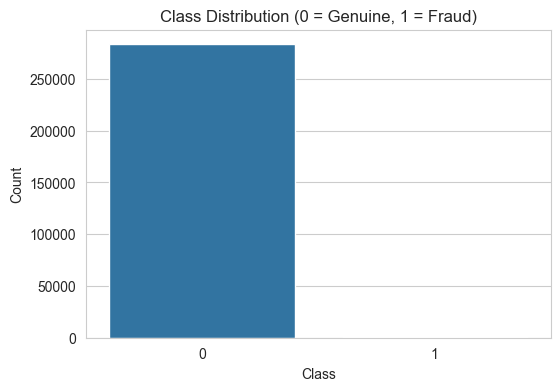

In [19]:
# Class distribution plot
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title('Class Distribution (0 = Genuine, 1 = Fraud)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.savefig("my_graph1.png", dpi=300, bbox_inches="tight")
plt.show()

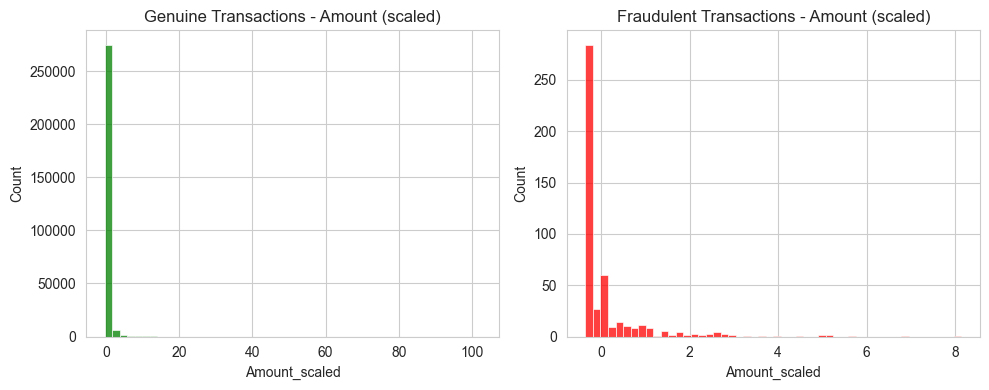

In [18]:
# Transaction amount distribution: fraud vs genuine
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(df[df['Class']==0]['Amount_scaled'], bins=50, color='green')
plt.title('Genuine Transactions - Amount (scaled)')

plt.subplot(1,2,2)
sns.histplot(df[df['Class']==1]['Amount_scaled'], bins=50, color='red')
plt.title('Fraudulent Transactions - Amount (scaled)')
plt.tight_layout()
plt.savefig("my_graph.png", dpi=300, bbox_inches="tight")
plt.show()

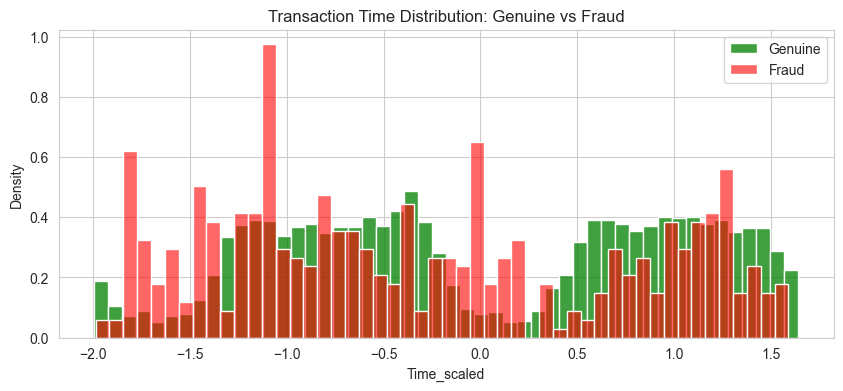

In [20]:
# Transactions over time
plt.figure(figsize=(10,4))
sns.histplot(df[df['Class']==0]['Time_scaled'], bins=50, color='green', label='Genuine', stat='density')
sns.histplot(df[df['Class']==1]['Time_scaled'], bins=50, color='red', label='Fraud', stat='density', alpha=0.6)
plt.legend()
plt.title('Transaction Time Distribution: Genuine vs Fraud')
plt.savefig("my_graph2.png", dpi=300, bbox_inches="tight")
plt.show()

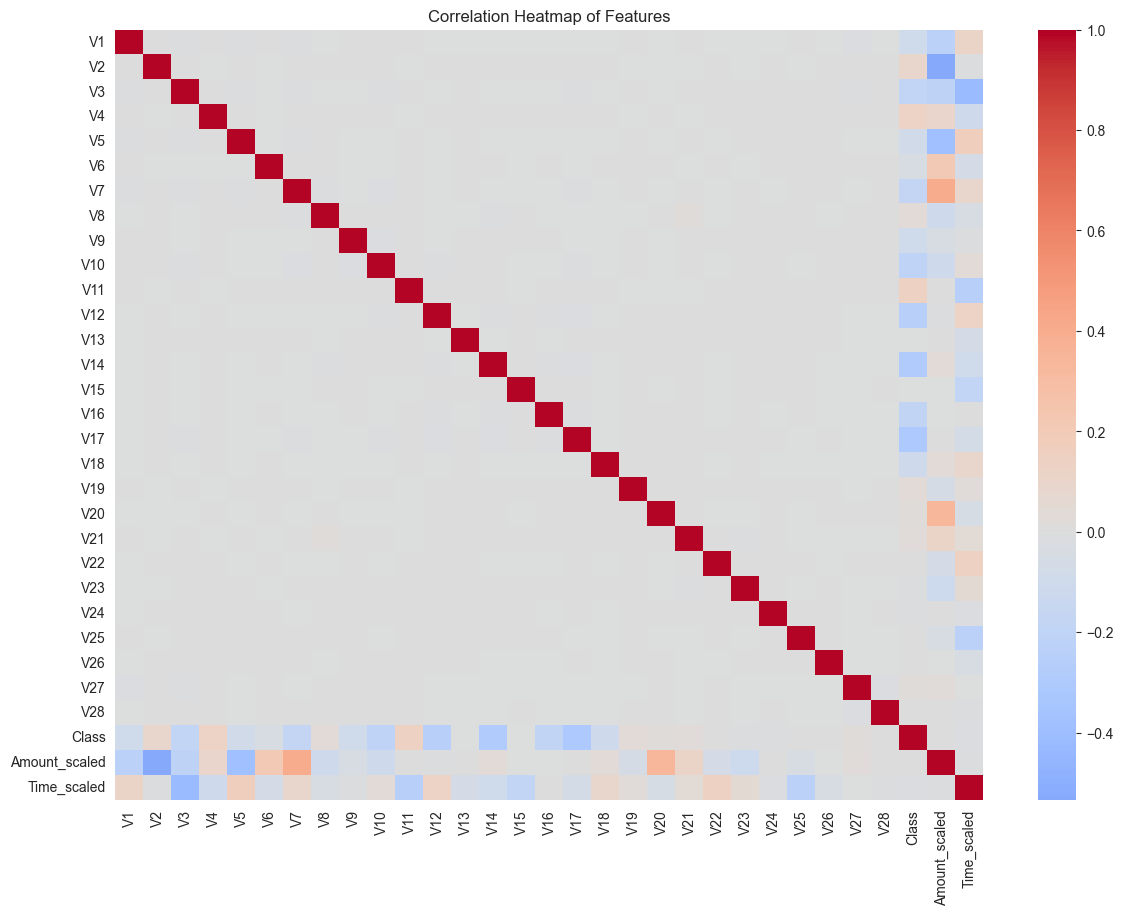

In [21]:
# Correlation heatmap
plt.figure(figsize=(14,10))
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Features')
plt.savefig("my_graph3.png", dpi=300, bbox_inches="tight")
plt.show()

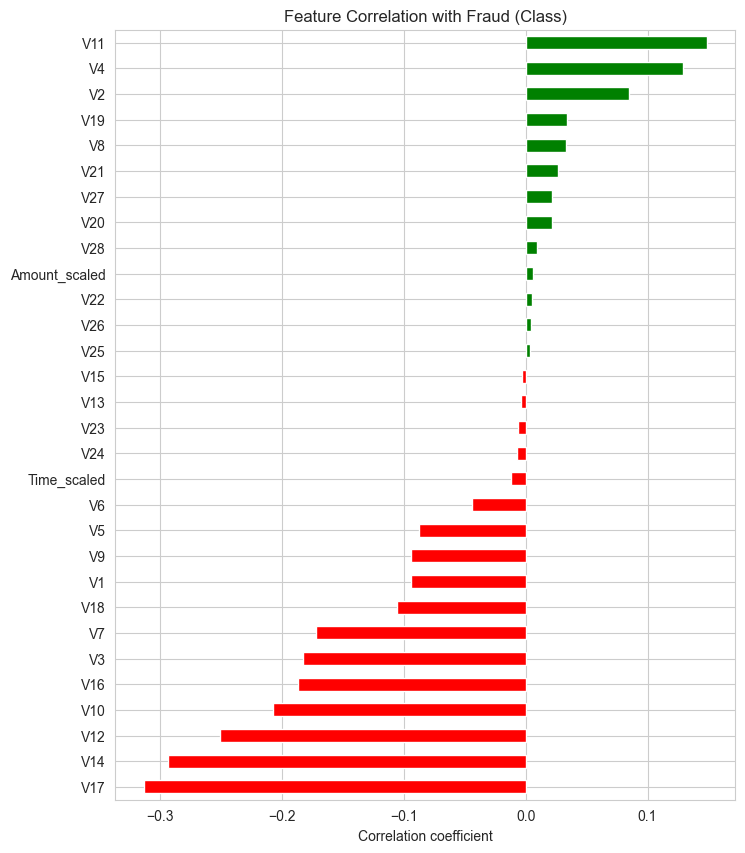

V17             -0.313498
V14             -0.293375
V12             -0.250711
V10             -0.206971
V16             -0.187186
V3              -0.182322
V7              -0.172347
V18             -0.105340
V1              -0.094486
V9              -0.094021
V5              -0.087812
V6              -0.043915
Time_scaled     -0.012359
V24             -0.007210
V23             -0.006333
V13             -0.003897
V15             -0.003300
V25              0.003202
V26              0.004265
V22              0.004887
Amount_scaled    0.005777
V28              0.009682
V20              0.021486
V27              0.021892
V21              0.026357
V8               0.033068
V19              0.033631
V2               0.084624
V4               0.129326
V11              0.149067
Name: Class, dtype: float64


In [22]:
# Which features correlate most strongly with Class (fraud)?
corr_with_class = corr['Class'].drop('Class').sort_values()
plt.figure(figsize=(8,10))
corr_with_class.plot(kind='barh', color=corr_with_class.apply(lambda x: 'red' if x<0 else 'green'))
plt.title('Feature Correlation with Fraud (Class)')
plt.xlabel('Correlation coefficient')
plt.savefig("my_graph4.png", dpi=300, bbox_inches="tight")
plt.show()

print(corr_with_class)

## 5. Train-Test Split & Handling Class Imbalance (SMOTE)

In [17]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Before SMOTE:", y_train.value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE:", y_train_res.value_counts().to_dict())

Before SMOTE: {0: 198277, 1: 331}
After SMOTE: {0: 198277, 1: 198277}


## 6. Build the Model — Decision Tree Classifier

In [13]:
dt_model = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42)
dt_model.fit(X_train_res, y_train_res)

y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

## 7. Model Evaluation

===== Decision Tree =====
              precision    recall  f1-score   support

           0     0.9997    0.9835    0.9915     84976
           1     0.0750    0.8028    0.1372       142

    accuracy                         0.9832     85118
   macro avg     0.5373    0.8931    0.5643     85118
weighted avg     0.9981    0.9832    0.9901     85118

ROC-AUC: 0.8936820769277689


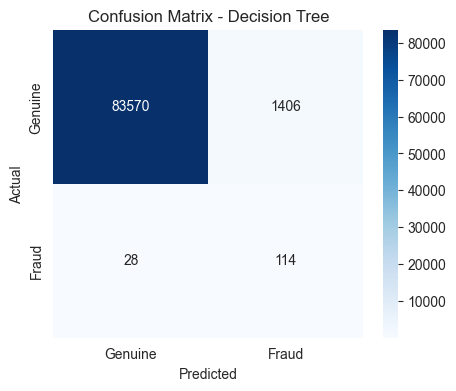

In [23]:
def evaluate_model(y_true, y_pred, y_proba, name):
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, digits=4))
    print("ROC-AUC:", roc_auc_score(y_true, y_proba))
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Genuine','Fraud'], yticklabels=['Genuine','Fraud'])
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.savefig("my_graph5.png", dpi=300, bbox_inches="tight")
    plt.show()

evaluate_model(y_test, y_pred_dt, y_proba_dt, "Decision Tree")

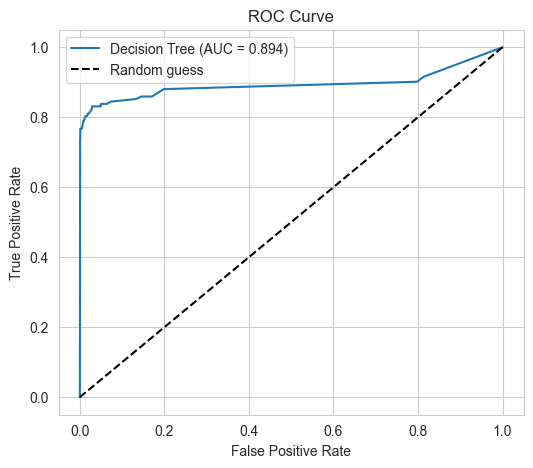

In [28]:
# ROC Curve comparison
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)

plt.figure(figsize=(6,5))
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_proba_dt):.3f})")
plt.plot([0,1],[0,1],'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.savefig("my_graph6.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Feature Importance — Major Characteristics of Fraudulent Transactions

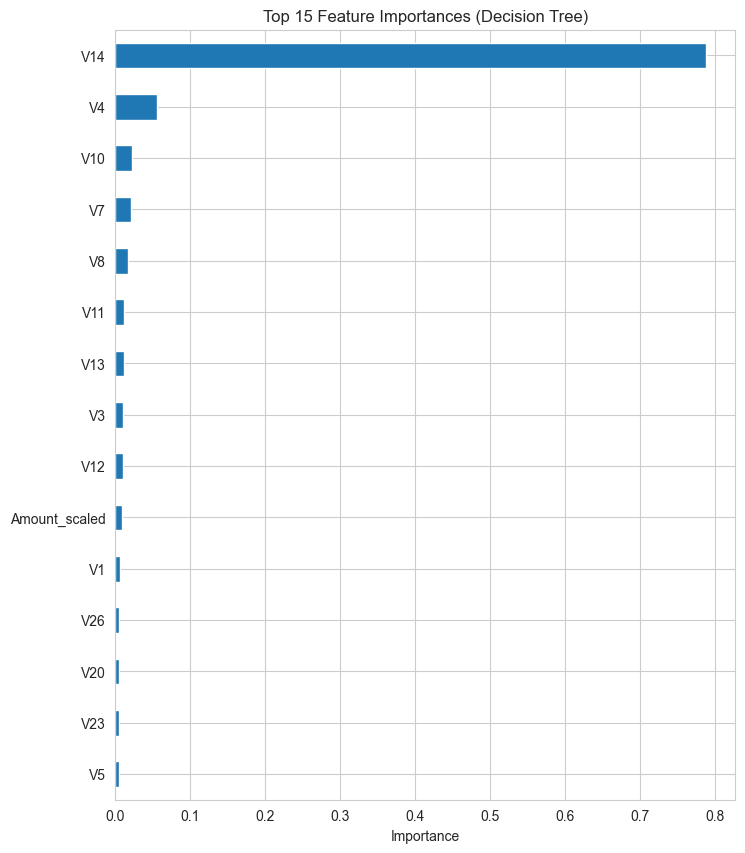

V14              0.787771
V4               0.055237
V10              0.022102
V7               0.020555
V8               0.017191
V11              0.010937
V13              0.010884
V3               0.010292
V12              0.009561
Amount_scaled    0.008177
V1               0.006284
V26              0.005303
V20              0.004450
V23              0.004433
V5               0.004244
dtype: float64


In [26]:
importances = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,10))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances (Decision Tree)')
plt.xlabel('Importance')
plt.savefig("my_graph7.png", dpi=300, bbox_inches="tight")
plt.show()

print(importances.head(15))